# 17. Correlated data and block averaging

**Track:** advanced &nbsp;·&nbsp; **Prerequisites:** Chapters 4 and 12

**Reading:** Allen & Tildesley, *Computer Simulation of Liquids* · Frenkel &
Smit, *Understanding Molecular Simulation* · Flyvbjerg & Petersen (1989) ·
Sokal (1997)

The standard error $s/\sqrt N$ assumes independent readings. Data recorded
as a time series are rarely independent: successive configurations of a
molecular dynamics or Monte Carlo simulation, a signal sampled faster than
its own relaxation time, daily values of a slowly drifting quantity. Each
new value then repeats part of what the previous one already said, and
$s/\sqrt N$ underestimates the uncertainty of the mean, often by a large
factor. An error bar that is five times too small is a common and serious
fault in simulation papers.

This notebook

1. derives the variance of the mean of a correlated series and introduces
   the integrated autocorrelation time;
2. uses a model series with a known answer to test the estimators;
3. presents the two standard remedies: integration of the autocorrelation
   function, and block averaging;
4. checks by simulation that the corrected error bars have the right
   coverage;
5. extends the block method to nonlinear quantities with the jackknife.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(12)

## 17.1 The variance of the mean of a correlated series

Let $x_1, \dots, x_N$ be a stationary series: its statistical properties do
not change along the series. It has mean $\mu$, variance $\sigma^2$, and a
normalised **autocorrelation function**

$$ \rho(t) = \frac{\langle (x_i - \mu)(x_{i+t} - \mu)\rangle}{\sigma^2} , \qquad \rho(0) = 1 , $$

which depends only on the separation $t$. The mean
$\bar x = \tfrac1N\sum_i x_i$ has variance

$$ \operatorname{var}(\bar x)
 = \frac{1}{N^2}\sum_{i=1}^{N}\sum_{j=1}^{N} \langle (x_i-\mu)(x_j-\mu)\rangle
 = \frac{\sigma^2}{N^2}\sum_{i,j}\rho(|i-j|) . $$

This is the propagation law with covariance (Section 12.1) applied to the
mean. In the double sum the separation $t = |i-j|$ occurs $N$ times for
$t=0$ and $2(N-t)$ times for $t \ge 1$, so

$$ \operatorname{var}(\bar x) = \frac{\sigma^2}{N}\left[1 + 2\sum_{t=1}^{N-1}\left(1 - \frac{t}{N}\right)\rho(t)\right] . $$

If the correlations decay over a time much shorter than the length of the
series, the factor $(1 - t/N)$ can be replaced by one and the sum extended
to infinity. Defining the **integrated autocorrelation time**

$$ \tau_\text{int} = \frac12 + \sum_{t=1}^{\infty}\rho(t) , $$

we obtain

> $$ \operatorname{var}(\bar x) = \frac{\sigma^2}{N}\,2\tau_\text{int} = \frac{\sigma^2}{N_\text{eff}} ,
>    \qquad N_\text{eff} = \frac{N}{2\tau_\text{int}} . $$

The series is worth $N_\text{eff}$ independent values: one for every
$2\tau_\text{int}$ steps. The naive standard error is too small by the
factor $\sqrt{2\tau_\text{int}}$. For independent data $\rho(t\ge1) = 0$,
$\tau_\text{int} = \tfrac12$ and the usual result is recovered. The quantity
$g = 2\tau_\text{int}$ is also called the statistical inefficiency.

Two remarks. First, $\tau_\text{int}$ is a property of the *observable*:
in the same simulation, the pressure may decorrelate in a hundred steps
and a slow structural quantity in a million. Second, saving data less
often does not lose much. Once the sampling interval approaches
$2\tau_\text{int}$, the saved values are nearly independent, and the error
bar is almost what it would be with every step saved.

## 17.2 A test series with a known answer

To test estimators we need a series whose $\tau_\text{int}$ is known
exactly. The first-order autoregressive process

$$ x_{i+1} = \phi\,x_i + \sqrt{1-\phi^2}\;\xi_i , \qquad \xi_i \sim N(0,1) , $$

is the discrete analogue of an overdamped particle in a harmonic well. It
has zero mean, unit variance, and $\rho(t) = \phi^{t}$ (multiply the
recursion by $x_i$ and average: $\rho(1) = \phi$, and so on). Hence

$$ \tau_\text{int} = \frac12 + \sum_{t=1}^{\infty}\phi^t = \frac12 + \frac{\phi}{1-\phi} = \frac{1+\phi}{2(1-\phi)} . $$

For $\phi = 0.9$ this gives $\tau_\text{int} = 9.5$: the naive standard
error is too small by $\sqrt{19} \approx 4.4$.

In [2]:
def ar1(phi, n, rng, n_series=None, burn=2000):
    """Stationary AR(1) series with zero mean and unit variance."""
    shape = (n + burn,) if n_series is None else (n_series, n + burn)
    xi = rng.normal(size=shape) * np.sqrt(1 - phi**2)
    return lfilter([1.0], [1.0, -phi], xi, axis=-1)[..., burn:]

phi = 0.9
tau_exact = 0.5 * (1 + phi) / (1 - phi)
N = 2**16
x = ar1(phi, N, rng)

sem_exact = np.sqrt(2 * tau_exact / N)          # sigma = 1
print(f"N = {N},  exact tau_int = {tau_exact:.2f}")
print(f"mean of the series        : {x.mean():+.4f}   (true value 0)")
print(f"naive standard error      : {ep.mean_sem(x)[2]:.4f}")
print(f"exact standard error      : {sem_exact:.4f}")
print(f"deviation of the mean from zero: {abs(x.mean()) / ep.mean_sem(x)[2]:.1f} naive standard errors, "
      f"{abs(x.mean()) / sem_exact:.1f} exact standard errors")

N = 65536,  exact tau_int = 9.50
mean of the series        : +0.0109   (true value 0)
naive standard error      : 0.0040
exact standard error      : 0.0170
deviation of the mean from zero: 2.8 naive standard errors, 0.6 exact standard errors


Judged by the naive error bar, the mean of this series deviates from the
true value by nearly three standard errors, which would be reported as a
significant effect. Judged by the correct error bar, it is well within
one.

## 17.3 Remedy 1: integrate the autocorrelation function

The direct approach is to estimate $\rho(t)$ from the data and sum it. The
difficulty is the tail. The estimate of $\rho(t)$ has a statistical noise
that does not decrease with $t$, while the true $\rho(t)$ decays to zero.
Summing far beyond the correlation time therefore adds only noise, and the
sum must be cut off at a window $M$:

$$ \hat\tau_\text{int}(M) = \frac12 + \sum_{t=1}^{M}\hat\rho(t) . $$

Too small a window truncates the true tail (bias); too large a window
accumulates noise (variance). A robust compromise is to choose the
smallest $M$ that satisfies $M \ge c\,\hat\tau_\text{int}(M)$ with
$c \approx 5$, known as automatic windowing. `ep.integrated_autocorrelation_time`
implements it.

In [3]:
tau_hat, window = ep.integrated_autocorrelation_time(x)
print(f"estimated tau_int = {tau_hat:.2f}  (window M = {window}),  exact {tau_exact:.2f}")
print(f"standard error from tau_int: {ep.sem_correlated(x):.4f},  exact {sem_exact:.4f}")

estimated tau_int = 9.64  (window M = 49),  exact 9.50
standard error from tau_int: 0.0174,  exact 0.0170


## 17.4 Remedy 2: block averaging

The second approach avoids $\rho(t)$ altogether. Cut the series into $n_b$
consecutive blocks of length $b$ and average within each block. If $b$ is
much longer than the correlation time, the block averages are practically
independent, and the ordinary formula applies to them:

$$ u_{\bar x} = \frac{s_b}{\sqrt{n_b}} , $$

with $s_b$ the standard deviation of the block averages.

How long is long enough? The answer is read from the data by a **blocking
analysis**: repeat the calculation for $b = 1, 2, 4, 8, \dots$ and plot the
estimated standard error against $b$. At $b = 1$ it is the naive value. As
$b$ grows, more of the correlation is contained inside the blocks and the
estimate rises. Once $b \gg \tau_\text{int}$ it stops rising: the plateau
is the standard error. For a series of the AR(1) type the approach is

$$ u(b) \simeq u_\infty\sqrt{1 - \frac{\tau_\text{c}}{b}\,\bigl(1 - e^{-b/\tau_\text{c}}\bigr)} $$

with $\tau_\text{c} = -1/\ln\phi$, which is within 5 % of the plateau for
$b \gtrsim 10\,\tau_\text{c}$.

The estimate at each block size has its own statistical uncertainty.
Since it is a standard deviation computed from $n_b$ values (Section 4.3),

$$ \frac{u\bigl(u(b)\bigr)}{u(b)} \approx \frac{1}{\sqrt{2(n_b - 1)}} , $$

so the right-hand end of the curve, where few blocks remain, is noisy. The
curve must be read with these error bars. **If no plateau is reached before
the error bars become large, the series is too short** to determine its
own uncertainty, and no method will rescue it.

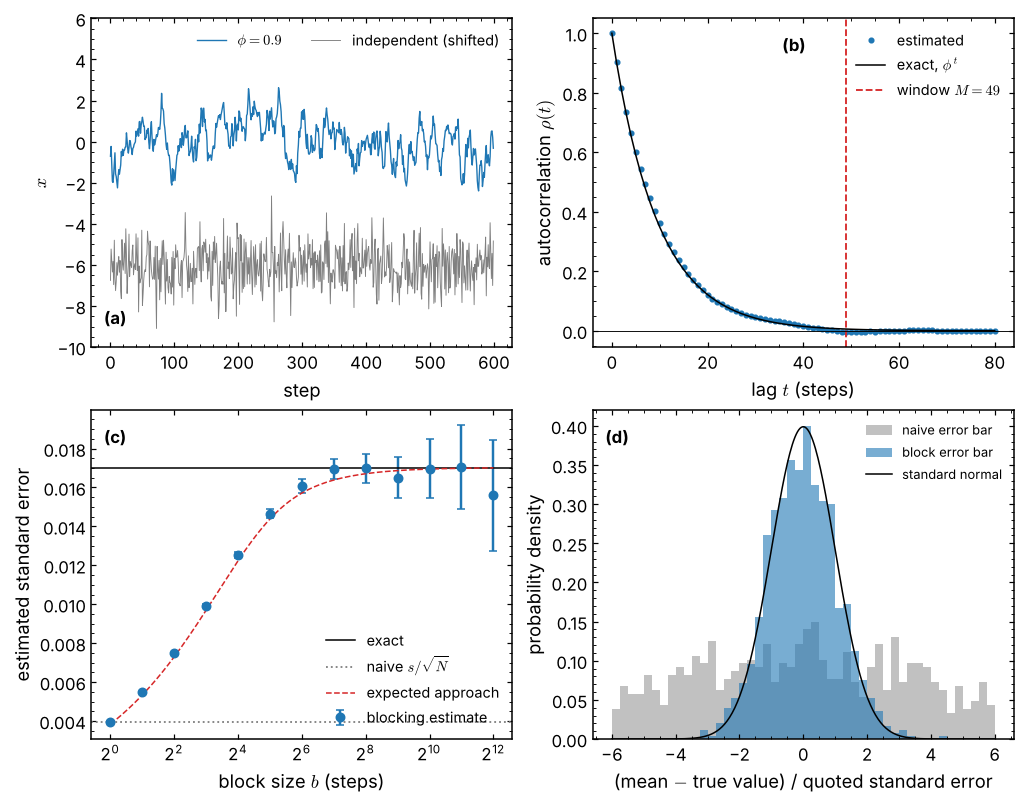

In [4]:
sizes, sem_b, err_b = ep.blocking_curve(x, min_blocks=16)

rho_hat = ep.autocorrelation(x, max_lag=80)
lags = np.arange(81)

# coverage experiment: many independent series, three error estimates each
n_series, n_len, block = 1000, 2**14, 512
X = ar1(phi, n_len, rng, n_series=n_series)
means = X.mean(axis=1)
naive = X.std(axis=1, ddof=1) / np.sqrt(n_len)
bm = X.reshape(n_series, n_len // block, block).mean(axis=2)
blocked = bm.std(axis=1, ddof=1) / np.sqrt(bm.shape[1])
from_tau = np.array([ep.sem_correlated(row) for row in X])
sem_true = np.sqrt(2 * tau_exact / n_len)

fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))
ax = axes[0, 0]
ax.plot(x[:600], "C0", lw=0.9, label=r"$\phi=0.9$")
ax.plot(rng.normal(size=600) - 6, color="0.5", lw=0.6, label="independent (shifted)")
ax.set_xlabel("step"); ax.set_ylabel("$x$"); ax.set_ylim(-10, 6)
ax.legend(loc="upper right", ncol=2); ep.panel_label(ax, "(a)", y=0.12)

ax = axes[0, 1]
ax.plot(lags, rho_hat, "o", ms=3, color="C0", label="estimated")
ax.plot(lags, phi**lags, "k-", lw=1, label=r"exact, $\phi^{t}$")
ax.axvline(window, color="C3", ls="--", lw=1.2, label=f"window $M={window}$")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("lag $t$ (steps)"); ax.set_ylabel(r"autocorrelation $\rho(t)$")
ax.legend(); ep.panel_label(ax, "(b)", x=0.45)

ax = axes[1, 0]
ax.errorbar(sizes, sem_b, yerr=err_b, fmt="o", color="C0", label="blocking estimate")
ax.axhline(sem_exact, color="k", lw=1, label="exact")
ax.axhline(ep.mean_sem(x)[2], color="0.5", ls=":", lw=1.2, label="naive $s/\\sqrt{N}$")
bb = np.logspace(0, np.log10(sizes[-1]), 200)
tc = -1 / np.log(phi)
ax.plot(bb, sem_exact * np.sqrt(1 - tc / bb * (1 - np.exp(-bb / tc))), "C3--", lw=1,
        label="expected approach")
ax.set_xscale("log", base=2)
ax.set_xlabel("block size $b$ (steps)"); ax.set_ylabel("estimated standard error")
ax.legend(loc="lower right"); ep.panel_label(ax, "(c)")

ax = axes[1, 1]
bins = np.linspace(-6, 6, 49)
ax.hist(means / naive, bins=bins, density=True, color="0.6", alpha=0.6, label="naive error bar")
ax.hist(means / blocked, bins=bins, density=True, color="C0", alpha=0.6, label="block error bar")
g = np.linspace(-6, 6, 300)
ax.plot(g, np.exp(-g**2 / 2) / np.sqrt(2 * np.pi), "k-", lw=1, label="standard normal")
ax.set_xlabel("(mean $-$ true value) / quoted standard error"); ax.set_ylabel("probability density")
ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(d)")
plt.show()

**Panel (a)** compares the correlated series with independent noise of the
same variance: the correlated series wanders, and stays on one side of
zero for tens of steps. **Panel (b)** shows the estimated autocorrelation
function, the exact $\phi^t$, and the summation window. **Panel (c)** is
the blocking curve: it starts at the naive value, rises, and levels off at
the exact standard error once the blocks are a hundred steps or more long,
in agreement with the expected approach.

**Panel (d)** is the test that matters. For 1000 independent series the
deviation of the mean from the true value is divided by the quoted error
bar. If the error bar is right, this ratio follows a standard normal
distribution. With the block error bar it does; with the naive one, the
distribution is more than four times too wide. The numbers:

In [5]:
def coverage(err, k):
    return np.mean(np.abs(means) < k * err)

print(f"true standard error of the mean (exact)      : {sem_true:.5f}")
print(f"standard deviation of the 1000 means         : {means.std(ddof=1):.5f}\n")
print("estimator                 typical value    within 1 u    within 2 u")
for name, err in (("naive s/sqrt(N)", naive), (f"blocks of {block}", blocked),
                  ("tau_int, auto window", from_tau)):
    print(f"{name:<24}  {np.median(err):.5f}         {coverage(err, 1):.3f}         {coverage(err, 2):.3f}")
print("expected for a correct error bar                0.683         0.954")

true standard error of the mean (exact)      : 0.03405
standard deviation of the 1000 means         : 0.03490

estimator                 typical value    within 1 u    within 2 u
naive s/sqrt(N)           0.00780         0.176         0.326
blocks of 512             0.03319         0.657         0.935
tau_int, auto window      0.03374         0.674         0.946
expected for a correct error bar                0.683         0.954


With the naive error bar the true value lies within one quoted standard
error in fewer than a fifth of the runs. Both corrected estimators restore
the expected coverage. The block estimate uses 32 blocks here, so its
coverage is a little below the normal values for the reason discussed in
Section 4.4 (an error bar estimated from few values calls for Student's
$t$, with $\nu = n_b - 1$).

### Which method?

| | Autocorrelation integral | Block averaging |
|---|---|---|
| Gives $\tau_\text{int}$ | yes | indirectly, $2\tau_\text{int} = [u_\infty/u(1)]^2$ |
| Precision for given data | somewhat better | limited by the number of blocks |
| Diagnostic | plot $\hat\rho(t)$ and the window | plateau of the blocking curve |
| Extends to derived quantities | awkward | easily, see below |

In practice it is sensible to use one and check with the other.

## 17.5 Derived quantities: the jackknife on blocks

Many observables are not simple averages but nonlinear functions of
averages: a heat capacity from the variance of the energy, a
compressibility from volume fluctuations, a ratio of two averages, a free
energy from $-k_\mathrm{B}T\ln\langle e^{-\beta\Delta U}\rangle$. Computing
the quantity separately in each block and taking the spread is tempting,
but a nonlinear function of a noisy block average is biased (Section 12.3),
and short blocks make the bias worse.

The **jackknife** avoids this. Instead of evaluating the quantity *on* each
block, evaluate it on *all the data except* one block:

$$ \theta_{(k)} = \theta(\text{all blocks but the } k\text{th}) , \qquad k = 1, \dots, n_b . $$

Each $\theta_{(k)}$ uses almost the whole series, so the nonlinearity does
little harm. The leave-one-out values are strongly correlated with one
another, which is accounted for by the factor $(n_b - 1)$ in

$$ u_\theta^2 = \frac{n_b - 1}{n_b}\sum_{k=1}^{n_b}\bigl(\theta_{(k)} - \bar\theta_{(\cdot)}\bigr)^2 . $$

For the mean itself this reduces exactly to $s_b/\sqrt{n_b}$.

As an example we estimate the variance $\langle x^2\rangle - \langle
x\rangle^2$ of the AR(1) series (true value 1), the prototype of all
fluctuation formulas.

In [6]:
def variance_from_blocks(blocks):
    """Variance of x from block averages of x (column 0) and x^2 (column 1)."""
    m = blocks.mean(axis=0)
    return m[1] - m[0]**2

n_blocks = 32
b = N // n_blocks
blocks = np.column_stack([ep.block_means(x, b), ep.block_means(x**2, b)])
var_hat, u_var = ep.jackknife(blocks, variance_from_blocks)
print("variance of x:", ep.format_result(var_hat, u_var), "  (true value 1)")

# check: spread of the same estimate over independent series of equal length
V = ar1(phi, N, rng, n_series=300)
print(f"spread of the estimate over 300 independent series: {V.var(axis=1).std(ddof=1):.4f}")
print(f"naive error bar assuming independent data         : {np.sqrt(2 / N) * var_hat:.4f}")

variance of x: 1.035 ± 0.018   (true value 1)


spread of the estimate over 300 independent series: 0.0169
naive error bar assuming independent data         : 0.0057


The jackknife error bar agrees with the actual spread over independent
series, within the precision to be expected from 32 blocks, and is about
three times the value obtained by treating the data as independent. (The
estimate itself lies about two standard errors above the true value. That
happens by chance about one time in twenty, and this is one of them.)

## 17.6 Two warnings

**Equilibration.** Everything above assumes a stationary series. The
initial part of a simulation, during which the system relaxes from its
starting configuration, is not a sample of the equilibrium distribution.
Including it biases the mean, and the bias decreases only as $1/N$. Discard
it. A drifting block average is the usual warning sign.

**Slow modes that were never sampled.** A blocking curve with a clean
plateau proves only that the correlations *visible in the data* have been
accounted for. If the system has a relaxation time longer than the whole
run, such as a barrier never crossed, the series looks stationary and the
error bar is confidently wrong. Statistical analysis cannot detect what
the simulation did not visit. Independent runs from different starting
points are the only defence.

## Summary

* For a correlated series, $\operatorname{var}(\bar x) = 2\tau_\text{int}\,\sigma^2/N$.
  The naive standard error is too small by $\sqrt{2\tau_\text{int}}$.
* $\tau_\text{int}$ can be obtained by summing the autocorrelation function
  up to a self-consistent window.
* Block averaging gives the standard error from the plateau of the blocking
  curve. No plateau means the run is too short.
* For nonlinear functions of averages, use the jackknife over blocks.
* None of this corrects for missing equilibration or unsampled slow modes.

## References

* M. P. Allen and D. J. Tildesley, *Computer Simulation of Liquids*, 2nd ed.
  (Oxford University Press, 2017).
* H. Flyvbjerg and H. G. Petersen, "Error estimates on averages of
  correlated data", *J. Chem. Phys.* **91**, 461 (1989).
* D. Frenkel and B. Smit, *Understanding Molecular Simulation*, 2nd ed.
  (Academic Press, 2002).
* A. D. Sokal, "Monte Carlo methods in statistical mechanics: foundations
  and new algorithms", in *Functional Integration: Basics and Applications*,
  edited by C. DeWitt-Morette, P. Cartier and A. Folacci (Plenum, New York,
  1997).

## Exercises

1. Generate AR(1) series with $\phi = 0.5$, $0.99$ and $0.999$, all of
   length $2^{16}$. Produce the blocking curve for each. For which is the
   series too short, and how does the curve tell you?
2. Keep only every 20th value of the $\phi = 0.9$ series. How do the naive
   and the exact standard errors of the mean change? Explain.
3. Show analytically that the jackknife formula reduces to $s/\sqrt n$ when
   $\theta$ is the mean.
4. Add a decaying transient $3\,e^{-i/2000}$ to the series and repeat the
   blocking analysis. What happens to the mean and to the curve? Then
   discard the first 10 000 steps and repeat.

---

**Previous:** [16. Rules of thumb, tested](../part3_data_analysis/16_rules_of_thumb_tested.ipynb) &nbsp;·&nbsp; **Next:** [18. Sensitivity analysis and uncertainty budgets](18_sensitivity_analysis_and_budgets.ipynb)